# Strawberry Ripeness Detection - Milestone 2
**Contents:** (1) Dataset  (2) Preprocessing  (3) Initial model  (4) Mid-project demo

Dataset: 6 ripeness stages - Early-Turning, Green, Late-Turning, Red, Turning, White


## 0. Setup

In [ ]:
import subprocess, sys, os, shutil, zipfile, json, random, warnings
from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore")


def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])


try:
    import ultralytics  # noqa: F401
except ImportError:
    pip_install("ultralytics")

import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---------------- EDIT THESE IF NEEDED ----------------
ZIP_PATH = Path("Strawberry-DS.zip")      # path to the zip you were given
WORK_DIR = Path("strawberry_project")     # everything is created inside this folder
IMG_MAX_SIDE = 1280                       # preprocessing: longest image side after resize
TRAIN_IMGSZ = 960                         # YOLO training / inference size (strawberries are small, so >640 helps)
# ------------------------------------------------------

# If the zip is not found and we are in Colab, ask for an upload
if not ZIP_PATH.exists() and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    ZIP_PATH = Path(next(iter(uploaded)))

assert ZIP_PATH.exists(), f"Cannot find {ZIP_PATH}. Upload it or fix ZIP_PATH."
WORK_DIR.mkdir(parents=True, exist_ok=True)
print("Zip file :", ZIP_PATH.resolve())
print("Work dir :", WORK_DIR.resolve())

Zip file : /content/Strawberry-DS.zip
Work dir : /content/strawberry_project


## 1. Dataset


In [ ]:
RAW_DIR = WORK_DIR / "raw"


def extract_recursive(zip_path, out_dir, max_depth=3):
    """Extract a zip and any zip files nested inside it."""
    out_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(out_dir)
    if max_depth == 0:
        return
    for inner in list(out_dir.rglob("*.zip")):
        target = inner.parent / (inner.stem + "_extracted")
        if not target.exists():
            extract_recursive(inner, target, max_depth - 1)


if not list(RAW_DIR.rglob("data.yaml")):
    extract_recursive(ZIP_PATH, RAW_DIR)

yaml_files = list(RAW_DIR.rglob("data.yaml"))
assert yaml_files, "data.yaml not found after extraction - check the zip contents."
DATA_ROOT = yaml_files[0].parent
print("Dataset root:", DATA_ROOT)

with open(DATA_ROOT / "data.yaml") as f:
    raw_cfg = yaml.safe_load(f)

CLASS_NAMES = list(raw_cfg["names"].values()) if isinstance(raw_cfg["names"], dict) else list(raw_cfg["names"])
NC = len(CLASS_NAMES)
print(f"Classes ({NC}):", CLASS_NAMES)

SPLITS = ["train", "valid", "test"]
for s in SPLITS:
    assert (DATA_ROOT / s / "images").exists(), f"Missing folder: {DATA_ROOT / s / 'images'}"

Dataset root: strawberry_project/raw/Strawberry-DS/Strawberry (2)_extracted
Classes (6): ['Early-Turning', 'Green', 'Late-Turning', 'Red', 'Turning', 'White']


### 1.2 Dataset summary, integrity check and class distribution

split  images  boxes  images_without_label
train     172    754                     0
valid      49    225                     0
 test      26    104                     0

Integrity problems found: 0

Image sizes (W x H): count
  (3840, 2160): 247

Boxes per class and split:
split          train  valid  test  total
class                                   
Early-Turning     25      7     2     34
Green            303    104    43    450
Late-Turning      39     14     3     56
Red              170     36    19    225
Turning           30     10     2     42
White            187     54    35    276


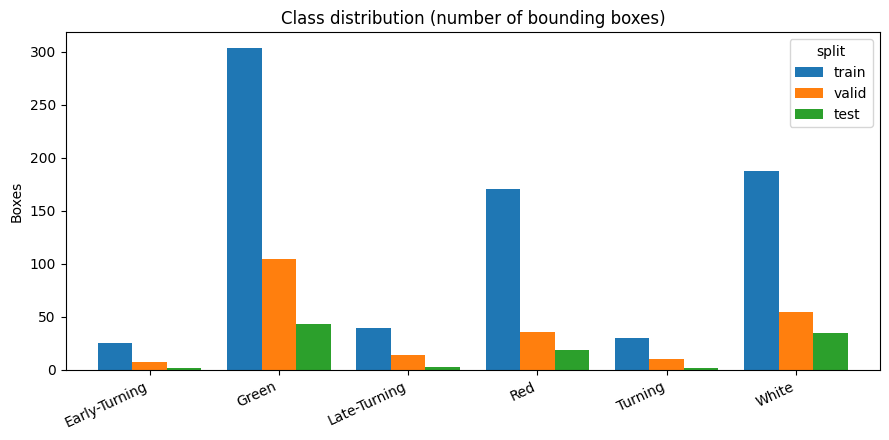

Imbalance ratio (largest / smallest class): 13.2x


In [ ]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def list_images(split_dir):
    return sorted(p for p in (split_dir / "images").iterdir() if p.suffix.lower() in IMG_EXTS)


def read_label_rows(label_path):
    rows = []
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) == 5:
                try:
                    rows.append((int(float(parts[0])), *map(float, parts[1:])))
                except ValueError:
                    pass
    return rows


summary, class_rows, problems = [], [], []
for s in SPLITS:
    imgs = list_images(DATA_ROOT / s)
    n_boxes, n_missing = 0, 0
    for p in imgs:
        lp = DATA_ROOT / s / "labels" / (p.stem + ".txt")
        if not lp.exists():
            n_missing += 1
            problems.append(f"{s}: no label file for {p.name}")
        for (c, x, y, w, h) in read_label_rows(lp):
            n_boxes += 1
            class_rows.append({"split": s, "class_id": c, "class": CLASS_NAMES[c]})
            if not (0 <= c < NC) or not all(0 <= v <= 1 for v in (x, y, w, h)):
                problems.append(f"{s}: out-of-range value in {lp.name}")
    summary.append({"split": s, "images": len(imgs), "boxes": n_boxes, "images_without_label": n_missing})

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))
print("\nIntegrity problems found:", len(problems))
for pr in problems[:10]:
    print("  -", pr)

# Image resolution statistics
sizes = Counter()
for s in SPLITS:
    for p in list_images(DATA_ROOT / s):
        im = cv2.imread(str(p))
        if im is not None:
            sizes[(im.shape[1], im.shape[0])] += 1
print("\nImage sizes (W x H): count")
for k, v in sizes.most_common():
    print(f"  {k}: {v}")

# Class distribution
cls_df = pd.DataFrame(class_rows)
dist = (cls_df.groupby(["class", "split"]).size().unstack(fill_value=0)
        .reindex(CLASS_NAMES).fillna(0).astype(int))
dist = dist.reindex(columns=[s for s in SPLITS if s in dist.columns])
dist["total"] = dist.sum(axis=1)
print("\nBoxes per class and split:")
print(dist.to_string())

ax = dist.drop(columns="total").plot(kind="bar", figsize=(9, 4.5), width=0.8)
ax.set_title("Class distribution (number of bounding boxes)")
ax.set_ylabel("Boxes")
ax.set_xlabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(WORK_DIR / "class_distribution.png", dpi=150)
plt.show()

ratio = dist["total"].max() / max(1, dist["total"].min())
print(f"Imbalance ratio (largest / smallest class): {ratio:.1f}x")

### 1.3 Visualise annotated samples and one example of each ripeness stage

In [ ]:
PALETTE = [(255, 140, 0), (0, 170, 0), (200, 0, 200), (230, 0, 0), (255, 200, 0), (120, 120, 120)]
PALETTE = (PALETTE * ((NC // len(PALETTE)) + 1))[:NC]


def draw_boxes(img_rgb, rows, thickness=None):
    out = img_rgb.copy()
    H, W = out.shape[:2]
    t = thickness or max(2, W // 400)
    for (c, x, y, w, h) in rows:
        x1, y1 = int((x - w / 2) * W), int((y - h / 2) * H)
        x2, y2 = int((x + w / 2) * W), int((y + h / 2) * H)
        cv2.rectangle(out, (x1, y1), (x2, y2), PALETTE[c], t)
        cv2.putText(out, CLASS_NAMES[c], (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.5, W / 1800), PALETTE[c], max(1, t - 1), cv2.LINE_AA)
    return out


def load_rgb(path, reduced=True):
    flag = cv2.IMREAD_REDUCED_COLOR_4 if reduced else cv2.IMREAD_COLOR
    im = cv2.imread(str(path), flag)
    if im is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)


train_imgs = list_images(DATA_ROOT / "train")
sample = random.Random(SEED).sample(train_imgs, min(6, len(train_imgs)))
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, p in zip(axes.ravel(), sample):
    rows = read_label_rows(DATA_ROOT / "train" / "labels" / (p.stem + ".txt"))
    ax.imshow(draw_boxes(load_rgb(p), rows))
    ax.set_title(p.name[:22], fontsize=9)
    ax.axis("off")
plt.suptitle("Annotated training samples", fontsize=13)
plt.tight_layout()
plt.savefig(WORK_DIR / "annotated_samples.png", dpi=130)
plt.show()

# One cropped example (largest box) per ripeness stage
best_crop = {}
for p in train_imgs:
    for (c, x, y, w, h) in read_label_rows(DATA_ROOT / "train" / "labels" / (p.stem + ".txt")):
        area = w * h
        if c not in best_crop or area > best_crop[c][0]:
            best_crop[c] = (area, p, (x, y, w, h))

fig, axes = plt.subplots(1, NC, figsize=(3 * NC, 3.4))
axes = np.atleast_1d(axes)
for c, ax in enumerate(axes):
    ax.axis("off")
    if c in best_crop:
        _, p, (x, y, w, h) = best_crop[c]
        im = load_rgb(p, reduced=False)
        H, W = im.shape[:2]
        x1, y1 = max(0, int((x - w / 2) * W)), max(0, int((y - h / 2) * H))
        x2, y2 = min(W, int((x + w / 2) * W)), min(H, int((y + h / 2) * H))
        ax.imshow(im[y1:y2, x1:x2])
    ax.set_title(CLASS_NAMES[c], fontsize=11)
plt.suptitle("The 6 ripeness stages", fontsize=13)
plt.tight_layout()
plt.savefig(WORK_DIR / "ripeness_stages.png", dpi=130)
plt.show()

## 2. Preprocessing
Steps applied:
1. **Label cleaning** - remove malformed rows, clip boxes to the image, keep empty label files for background images.
2. **Resizing** - the original 3840x2160 images are too large for training, so they are resized
   (aspect ratio kept) so that the longest side is `IMG_MAX_SIDE` pixels. YOLO labels are normalised (0-1),
   so they stay valid after resizing.
3. **New `data.yaml`** with absolute paths (the original one uses relative `../train` paths that often fail).
4. **Augmentation** - done on-the-fly during training by YOLO (mosaic, HSV colour jitter, horizontal flip, scale,
   translate). A preview is shown below.

In [ ]:
PROC_DIR = WORK_DIR / "processed"


def clean_label_rows(src_path, nc):
    kept, dropped = [], 0
    if not src_path.exists():
        return kept, dropped
    for line in src_path.read_text().splitlines():
        parts = line.split()
        if not parts:
            continue
        if len(parts) != 5:
            dropped += 1
            continue
        try:
            c = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            dropped += 1
            continue
        if not (0 <= c < nc) or w <= 0 or h <= 0:
            dropped += 1
            continue
        x1, y1 = max(0.0, x - w / 2), max(0.0, y - h / 2)
        x2, y2 = min(1.0, x + w / 2), min(1.0, y + h / 2)
        w2, h2 = x2 - x1, y2 - y1
        if w2 <= 0 or h2 <= 0:
            dropped += 1
            continue
        kept.append(f"{c} {x1 + w2 / 2:.6f} {y1 + h2 / 2:.6f} {w2:.6f} {h2:.6f}")
    return kept, dropped


def preprocess_split(split):
    out_img = PROC_DIR / split / "images"
    out_lbl = PROC_DIR / split / "labels"
    out_img.mkdir(parents=True, exist_ok=True)
    out_lbl.mkdir(parents=True, exist_ok=True)
    n_ok, n_bad, n_dropped = 0, 0, 0
    for p in list_images(DATA_ROOT / split):
        im = cv2.imread(str(p))
        if im is None:
            n_bad += 1
            continue
        h, w = im.shape[:2]
        scale = min(1.0, IMG_MAX_SIDE / max(h, w))
        if scale < 1.0:
            im = cv2.resize(im, (int(round(w * scale)), int(round(h * scale))), interpolation=cv2.INTER_AREA)
        # short, clean file name (Roboflow names are very long)
        new_stem = p.stem.split(".rf.")[0].replace(" ", "_")
        if (out_img / f"{new_stem}.jpg").exists():          # avoid name collisions
            new_stem = f"{new_stem}_{p.stem[-6:]}"
        cv2.imwrite(str(out_img / f"{new_stem}.jpg"), im, [cv2.IMWRITE_JPEG_QUALITY, 95])
        rows, dropped = clean_label_rows(DATA_ROOT / split / "labels" / (p.stem + ".txt"), NC)
        (out_lbl / f"{new_stem}.txt").write_text("\n".join(rows) + ("\n" if rows else ""))
        n_ok += 1
        n_dropped += dropped
    return n_ok, n_bad, n_dropped


if PROC_DIR.exists():
    shutil.rmtree(PROC_DIR)          # always rebuild so reruns are consistent

for s in SPLITS:
    ok, bad, dropped = preprocess_split(s)
    print(f"{s:6s}: processed {ok} images | unreadable {bad} | invalid label rows dropped {dropped}")

# New data.yaml with ABSOLUTE paths
DATA_YAML = PROC_DIR / "data.yaml"
with open(DATA_YAML, "w") as f:
    yaml.safe_dump({
        "path": str(PROC_DIR.resolve()),
        "train": "train/images",
        "val": "valid/images",
        "test": "test/images",
        "nc": NC,
        "names": CLASS_NAMES,
    }, f, sort_keys=False)
print("\nWrote", DATA_YAML)
print(DATA_YAML.read_text())


def folder_size_mb(folder):
    return sum(f.stat().st_size for f in folder.rglob("*") if f.is_file()) / 1e6


print(f"Size before: {sum(folder_size_mb(DATA_ROOT / s / 'images') for s in SPLITS):8.1f} MB")
print(f"Size after : {sum(folder_size_mb(PROC_DIR / s / 'images') for s in SPLITS):8.1f} MB")

train : processed 172 images | unreadable 0 | invalid label rows dropped 0
valid : processed 49 images | unreadable 0 | invalid label rows dropped 0
test  : processed 26 images | unreadable 0 | invalid label rows dropped 0

Wrote strawberry_project/processed/data.yaml
path: /content/strawberry_project/processed
train: train/images
val: valid/images
test: test/images
nc: 6
names:
- Early-Turning
- Green
- Late-Turning
- Red
- Turning
- White

Size before:    293.1 MB
Size after :    103.6 MB


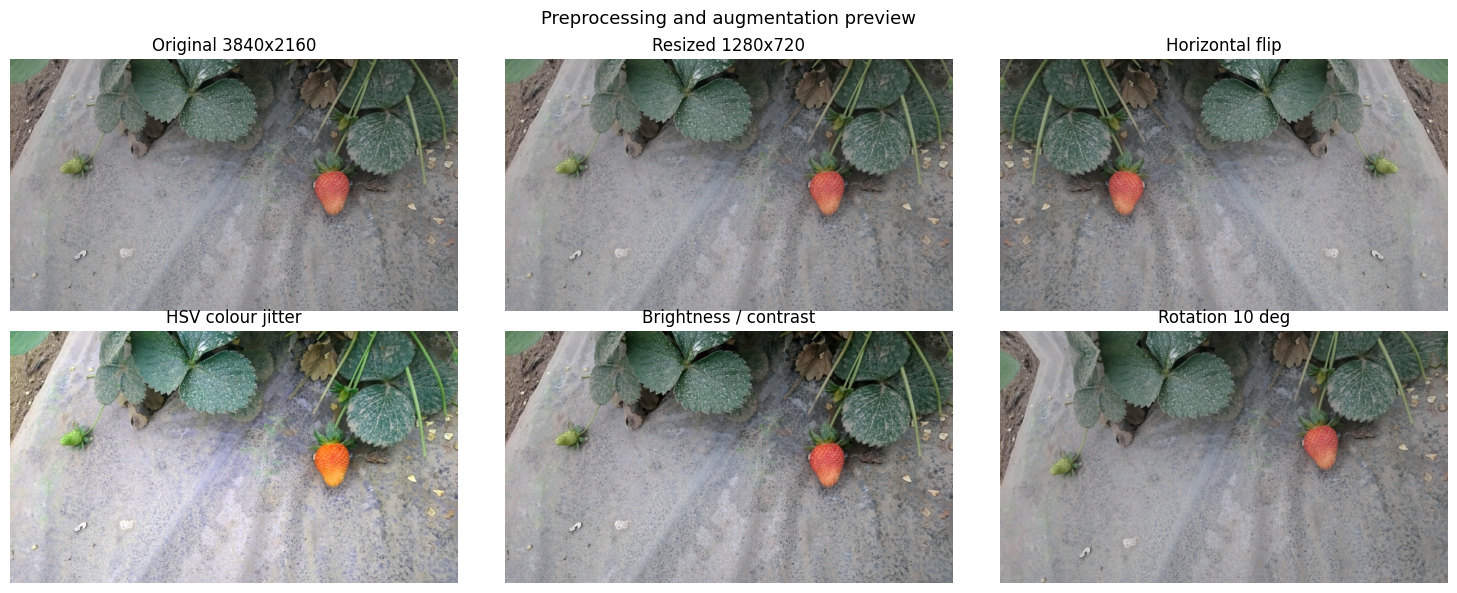

In [ ]:
# Before / after preprocessing + augmentation preview
p0 = train_imgs[0]
orig = cv2.cvtColor(cv2.imread(str(p0)), cv2.COLOR_BGR2RGB)
proc_path = sorted((PROC_DIR / "train" / "images").glob("*.jpg"))[0]
proc = cv2.cvtColor(cv2.imread(str(proc_path)), cv2.COLOR_BGR2RGB)


def hsv_jitter(img, dh=8, ds=1.4, dv=1.3):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + dh) % 180
    hsv[..., 1] = np.clip(hsv[..., 1] * ds, 0, 255)
    hsv[..., 2] = np.clip(hsv[..., 2] * dv, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)


def rotate(img, angle=10):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)


panels = [
    (f"Original {orig.shape[1]}x{orig.shape[0]}", orig),
    (f"Resized {proc.shape[1]}x{proc.shape[0]}", proc),
    ("Horizontal flip", cv2.flip(proc, 1)),
    ("HSV colour jitter", hsv_jitter(proc)),
    ("Brightness / contrast", cv2.convertScaleAbs(proc, alpha=1.2, beta=-20)),
    ("Rotation 10 deg", rotate(proc, 10)),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, (title, im) in zip(axes.ravel(), panels):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle("Preprocessing and augmentation preview", fontsize=13)
plt.tight_layout()
plt.savefig(WORK_DIR / "preprocessing_preview.png", dpi=130)
plt.show()

## 3. Initial model

In [ ]:
import torch
from ultralytics import YOLO

HAS_GPU = torch.cuda.is_available()
DEVICE = 0 if HAS_GPU else "cpu"
EPOCHS = 40 if HAS_GPU else 5          # CPU is slow, so only a quick sanity run
BATCH = 8 if HAS_GPU else 2
print("GPU available:", HAS_GPU, "| epochs:", EPOCHS, "| batch:", BATCH)
if not HAS_GPU:
    print("WARNING: no GPU detected. In Colab use Runtime > Change runtime type > GPU for a proper run.")

RUNS_DIR = (WORK_DIR / "runs").resolve()
model = YOLO("yolov8n.pt")

results = model.train(
    data=str(DATA_YAML.resolve()),
    epochs=EPOCHS,
    imgsz=TRAIN_IMGSZ,
    batch=BATCH,
    device=DEVICE,
    workers=2,
    seed=SEED,
    patience=15,
    project=str(RUNS_DIR),
    name="strawberry_yolov8n",
    exist_ok=True,
    plots=True,
    # augmentation (defaults made explicit)
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    fliplr=0.5, flipud=0.0,
    mosaic=1.0, scale=0.5, translate=0.1,
)

SAVE_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = SAVE_DIR / "weights" / "best.pt"
if not BEST_WEIGHTS.exists():
    BEST_WEIGHTS = SAVE_DIR / "weights" / "last.pt"
print("Training finished. Weights:", BEST_WEIGHTS)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU available: True | epochs: 40 | batch: 8
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/strawberry_project/processed/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=Tru

### 3.1 Training curves

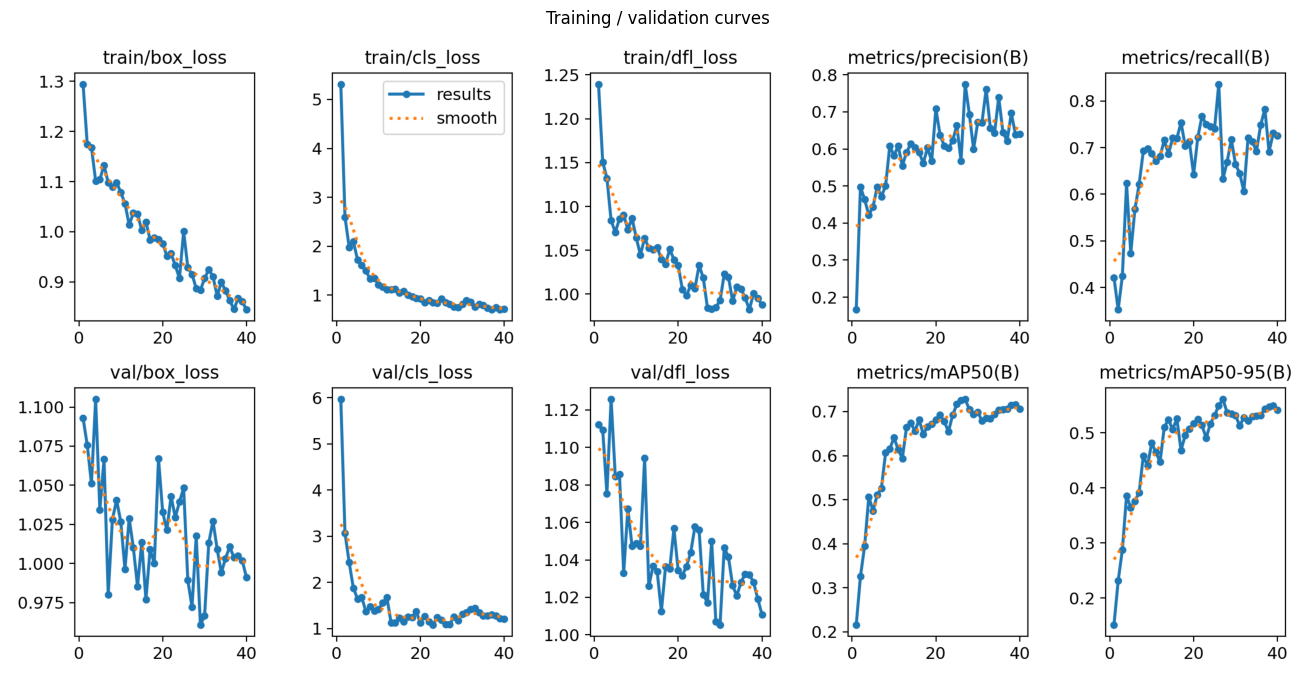

In [ ]:
curves = SAVE_DIR / "results.png"
if curves.exists():
    plt.figure(figsize=(14, 7))
    plt.imshow(plt.imread(str(curves)))
    plt.axis("off")
    plt.title("Training / validation curves")
    plt.tight_layout()
    plt.show()
else:
    print("results.png not found in", SAVE_DIR)

### 3.2 Evaluation on the validation and test sets

In [ ]:
best_model = YOLO(str(BEST_WEIGHTS))


def evaluate(split, run_name):
    m = best_model.val(
        data=str(DATA_YAML.resolve()),
        split=split,
        imgsz=TRAIN_IMGSZ,
        batch=BATCH,
        device=DEVICE,
        plots=True,
        project=str(RUNS_DIR),
        name=run_name,
        exist_ok=True,
        verbose=False,
    )
    per_class = []
    for i, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        per_class.append({"class": CLASS_NAMES[int(c)], "precision": p, "recall": r, "mAP50": ap50, "mAP50-95": ap})
    overall = {"split": split, "precision": float(m.box.mp), "recall": float(m.box.mr),
               "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map)}
    return overall, pd.DataFrame(per_class), Path(m.save_dir)


val_overall, val_per_class, val_dir = evaluate("val", "eval_val")
test_overall, test_per_class, test_dir = evaluate("test", "eval_test")

overall_df = pd.DataFrame([val_overall, test_overall]).set_index("split").round(3)
print("Overall metrics:")
print(overall_df.to_string())
print("\nPer-class metrics (TEST set):")
print(test_per_class.round(3).to_string(index=False))

overall_df.to_csv(WORK_DIR / "metrics_overall.csv")
test_per_class.round(4).to_csv(WORK_DIR / "metrics_per_class_test.csv", index=False)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3551.1±759.3 MB/s, size: 437.5 KB)
val: Scanning /content/strawberry_project/processed/valid/labels.cache... 49 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 14.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.3it/s 3.0s
                   all         49        225      0.781      0.637      0.728      0.558
Speed: 13.5ms preprocess, 15.0ms inference, 0.0ms loss, 4.4ms postprocess per image
Results saved to /content/strawberry_project/runs/eval_val
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4199.4±405.8 MB/s, size: 391.4

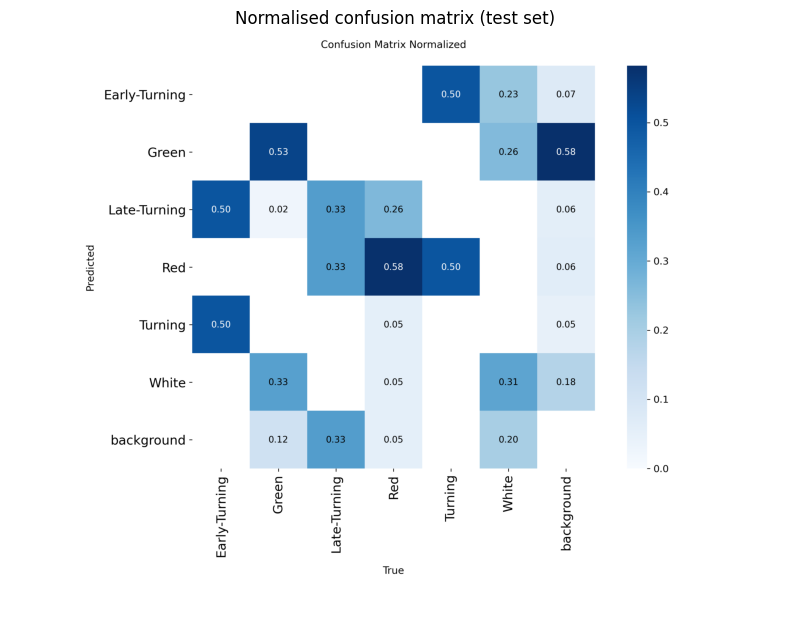

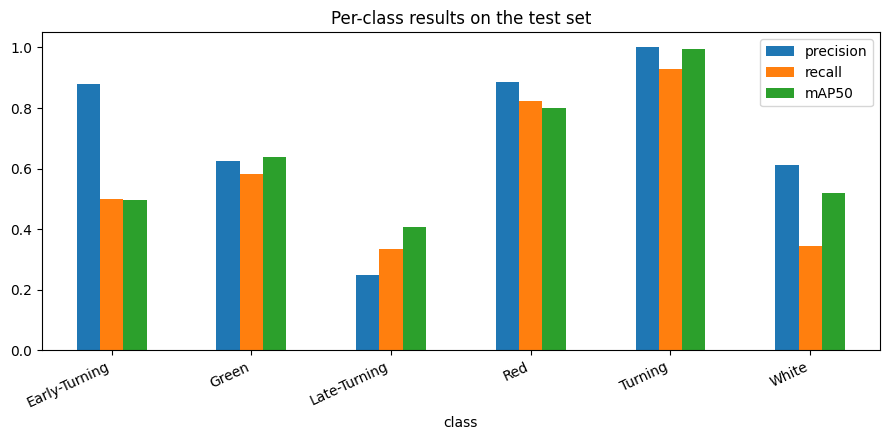

In [ ]:
# Confusion matrix + per-class bar chart (test set)
cm_path = test_dir / "confusion_matrix_normalized.png"
if cm_path.exists():
    plt.figure(figsize=(8, 7))
    plt.imshow(plt.imread(str(cm_path)))
    plt.axis("off")
    plt.title("Normalised confusion matrix (test set)")
    plt.tight_layout()
    plt.show()

if len(test_per_class):
    test_per_class.set_index("class")[["precision", "recall", "mAP50"]].plot(kind="bar", figsize=(9, 4.5))
    plt.title("Per-class results on the test set")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(WORK_DIR / "per_class_test.png", dpi=150)
    plt.show()

## 4. Model Demonstration
### 4.1 Predictions on unseen test images

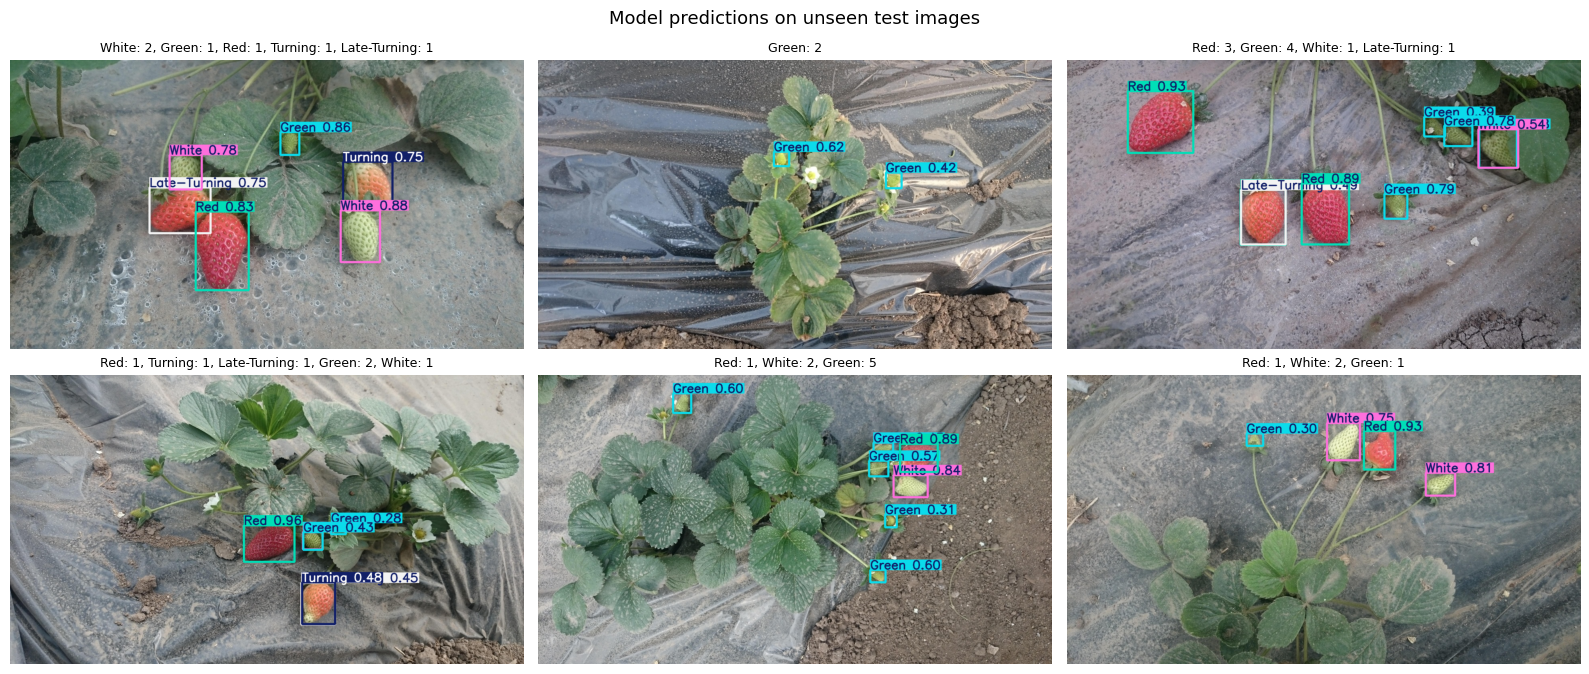

In [ ]:
CONF = 0.25


def predict_image(img_rgb, conf=CONF):
    """Run the detector on an RGB numpy image. Returns (annotated RGB image, {class: count})."""
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)            # ultralytics expects BGR arrays
    res = best_model.predict(source=bgr, conf=float(conf), imgsz=TRAIN_IMGSZ, device=DEVICE, verbose=False)[0]
    annotated = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)
    counts = Counter(CLASS_NAMES[int(c)] for c in res.boxes.cls.tolist()) if res.boxes is not None else Counter()
    return annotated, dict(counts)


test_imgs = sorted((PROC_DIR / "test" / "images").glob("*.jpg"))
demo_imgs = random.Random(SEED).sample(test_imgs, min(6, len(test_imgs)))

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, p in zip(axes.ravel(), demo_imgs):
    rgb = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    annotated, counts = predict_image(rgb)
    ax.imshow(annotated)
    ax.set_title(", ".join(f"{k}: {v}" for k, v in counts.items()) or "no detections", fontsize=9)
    ax.axis("off")
plt.suptitle("Model predictions on unseen test images", fontsize=13)
plt.tight_layout()
plt.savefig(WORK_DIR / "demo_predictions.png", dpi=130)
plt.show()

### 4.2 Ground truth vs prediction (side by side)

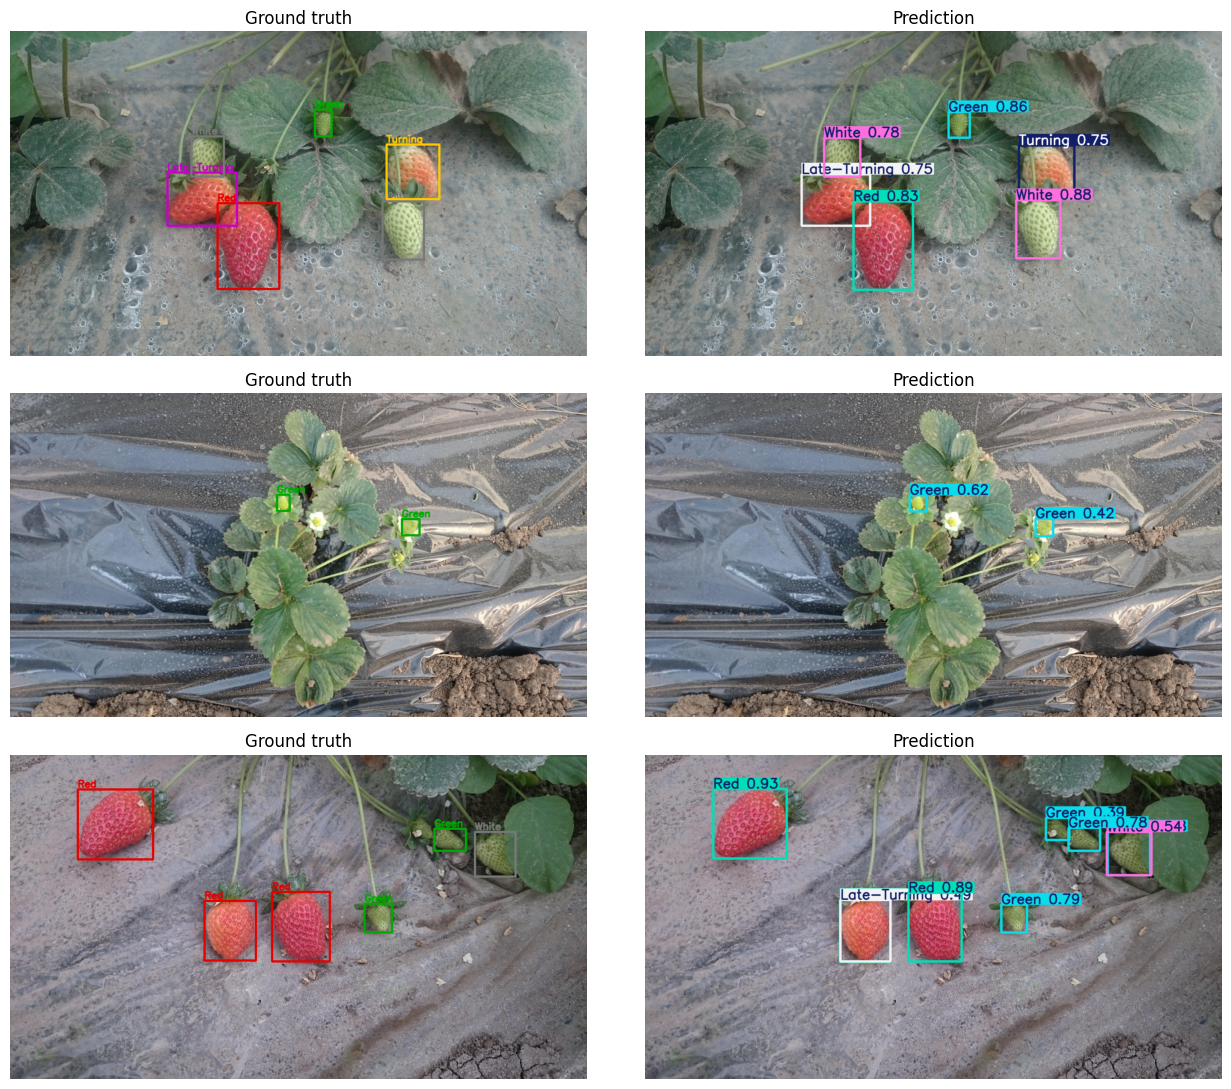

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(13, 11))
for row, p in zip(axes, demo_imgs[:3]):
    rgb = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    gt_rows = read_label_rows(PROC_DIR / "test" / "labels" / (p.stem + ".txt"))
    row[0].imshow(draw_boxes(rgb, gt_rows))
    row[0].set_title("Ground truth")
    row[1].imshow(predict_image(rgb)[0])
    row[1].set_title("Prediction")
    for a in row:
        a.axis("off")
plt.tight_layout()
plt.savefig(WORK_DIR / "gt_vs_pred.png", dpi=130)
plt.show()

### 4.3 Live Ripeness Detector - upload any strawberry photo

In [ ]:
LAUNCH_GRADIO = True

if LAUNCH_GRADIO:
    try:
        try:
            import gradio as gr
        except ImportError:
            pip_install("gradio")
            import gradio as gr

        def gradio_fn(image, conf):
            if image is None:
                return None, "Please upload an image."
            annotated, counts = predict_image(image, conf)
            if not counts:
                return annotated, "No strawberries detected. Try lowering the confidence threshold."
            text = "\n".join(f"{k}: {v}" for k, v in sorted(counts.items()))
            return annotated, f"Total detected: {sum(counts.values())}\n{text}"

        demo = gr.Interface(
            fn=gradio_fn,
            inputs=[gr.Image(type="numpy", label="Strawberry image"),
                    gr.Slider(0.05, 0.95, value=CONF, step=0.05, label="Confidence threshold")],
            outputs=[gr.Image(label="Detections"), gr.Textbox(label="Ripeness counts")],
            title="Strawberry Ripeness Detector (Milestone 2 demo)",
            description="Detects strawberries and classifies 6 ripeness stages: " + ", ".join(CLASS_NAMES),
            flagging_mode="never",
        )
        demo.launch(share=IN_COLAB, debug=False)
    except Exception as e:                      # the notebook must not crash if Gradio has a problem
        print("Gradio demo could not be started:", repr(e))
        print("The static demo results above are still valid.")

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3d4ae563a8becbe834.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 5. Save everything for the report / presentation

In [ ]:
export_dir = WORK_DIR / "milestone2_outputs"
export_dir.mkdir(exist_ok=True)
shutil.copy(BEST_WEIGHTS, export_dir / "best.pt")
for name in ["class_distribution.png", "annotated_samples.png", "ripeness_stages.png",
             "preprocessing_preview.png", "demo_predictions.png", "gt_vs_pred.png",
             "per_class_test.png", "metrics_overall.csv", "metrics_per_class_test.csv"]:
    if (WORK_DIR / name).exists():
        shutil.copy(WORK_DIR / name, export_dir / name)
for extra in [SAVE_DIR / "results.png", test_dir / "confusion_matrix_normalized.png"]:
    if extra.exists():
        shutil.copy(extra, export_dir / extra.name)

shutil.make_archive(str(WORK_DIR / "milestone2_outputs"), "zip", export_dir)
print("Saved:", (WORK_DIR / "milestone2_outputs.zip").resolve())
if IN_COLAB:
    from google.colab import files
    files.download(str(WORK_DIR / "milestone2_outputs.zip"))

Saved: /content/strawberry_project/milestone2_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>